In [20]:
import os
from typing import Literal, Optional
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.checkpoint.memory import MemorySaver

from dotenv import load_dotenv
load_dotenv()

GROQ_API_KEY=os.getenv('GROQ_API_KEY')

In [21]:
model = ChatGroq(model="openai/gpt-oss-120b", temperature=0)

In [22]:
class DraftReviewState(MessagesState):
    human_request: str
    human_comment: Optional[str]
    status: Literal["approved", "feedback"]
    assistant_response: str

In [23]:
def assistant_draft(state: DraftReviewState) -> DraftReviewState:
    user_message = HumanMessage(content=state["human_request"])
    status = state.get("status", "approved")

    if (status == "feedback" and state.get("human_comment")):
        human_comment = HumanMessage(content=state["human_comment"])

        system_message = SystemMessage(content=(f"""
        You are an AI assistant revising your previous draft. Carefully review the human's 
        feedback and update your reply accordingly. Address all comments, corrections, 
        or suggestions provided by the human. Ensure your revised response fully 
        integrates the feedback, improves clarity, and resolves any issues raised.
        """))

        messages = [user_message] + state["messages"] + [system_message, human_comment]
        all_messages = state["messages"] + [human_comment]

    else:
        system_message = SystemMessage(content=("""
        You are an AI assistant. Your goal is to fully understand and fulfill the user's 
        request by preparing a relevant, clear, and helpful draft reply. Focus on addressing 
        the user's needs directly and comprehensively. 
        Do not reference any previous human feedback at this stage.
        """))
        messages = [system_message, user_message]
        all_messages = state["messages"]
    
    response = model.invoke(messages)

    all_messages = all_messages + [response]

    return {
        **state,
        "messages": all_messages,
        "assistant_response": response.content
    }
    

In [24]:
def human_feedback(state: DraftReviewState):
    pass


def assistant_finalize(state: DraftReviewState) -> DraftReviewState:
    system_message = """
    You are an AI assistant. The user has approved your draft. Carefully 
    review your reply and make any final improvements to clarity, tone, and 
    completeness. Ensure the response is polished, professional, and ready 
    to be delivered as the final answer.
    """
    messages = [system_message] + state["messages"]
    response = model.invoke(messages)

    all_messages = state['messages'] + [response]

    return {
        **state,
        "messages": all_messages,
        "assistant_response": response.content
    }

In [25]:
def feedback_router(state: DraftReviewState) -> str:
    if state['status'] == 'approved':
        return 'assistant_finalize'
    else:
        return 'assistant_draft'

In [26]:
builder = StateGraph(DraftReviewState)

builder.add_node('assistant_draft', assistant_draft)
builder.add_node('human_feedback', human_feedback)
builder.add_node('assistant_finalize', assistant_finalize)

builder.add_edge(START, 'assistant_draft')
builder.add_edge('assistant_draft', 'human_feedback')
builder.add_conditional_edges('human_feedback', feedback_router, {'assistant_finalize': 'assistant_finalize', 'assistant_draft': 'assistant_draft'})
builder.add_edge('assistant_finalize', END)

graph = builder.compile(interrupt_before=["human_feedback"])

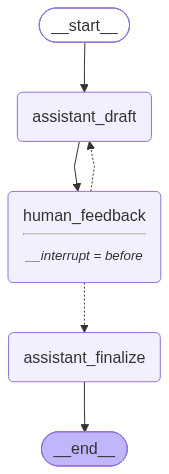

In [27]:
memory = MemorySaver()
graph = builder.compile(interrupt_before=["human_feedback"], checkpointer=memory)
graph

In [28]:
config = {
    "configurable": {
        "thread_id": "1"
    }
}

res = graph.invoke(input={"human_request": "What is the capital of France?"}, config=config)
res

{'messages': [AIMessage(content='The capital of France is **Paris**.', additional_kwargs={'reasoning_content': 'The user asks: "What is the capital of France?" Straightforward answer: Paris. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 140, 'total_tokens': 180, 'completion_time': 0.083312083, 'prompt_time': 0.0058844, 'queue_time': 0.316231579, 'total_time': 0.089196483, 'completion_tokens_details': {'reasoning_tokens': 22}}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4200b3f836', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--7e17645b-3437-48fc-8a0b-fb5631dacc32-0', usage_metadata={'input_tokens': 140, 'output_tokens': 40, 'total_tokens': 180})],
 'human_request': 'What is the capital of France?',
 'assistant_response': 'The capital of France is **Paris**.'}

In [29]:
graph.update_state(config,
                   {"human_comment": "Please provide more details about the capital city.", 
                            "status": "feedback"
                            }
                   )

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1e702f-a3e7-6493-8002-81e1c0510149'}}

In [30]:
new = graph.invoke(None , config=config)

In [31]:
new

{'messages': [AIMessage(content='The capital of France is **Paris**.', additional_kwargs={'reasoning_content': 'The user asks: "What is the capital of France?" Straightforward answer: Paris. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 140, 'total_tokens': 180, 'completion_time': 0.083312083, 'prompt_time': 0.0058844, 'queue_time': 0.316231579, 'total_time': 0.089196483, 'completion_tokens_details': {'reasoning_tokens': 22}}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4200b3f836', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--7e17645b-3437-48fc-8a0b-fb5631dacc32-0', usage_metadata={'input_tokens': 140, 'output_tokens': 40, 'total_tokens': 180}),
  HumanMessage(content='Please provide more details about the capital city.', additional_kwargs={}, response_metadata={}, id='42cd50b8-f95f-4137-8281-996d646450e1'),
  AIMessage(content='**Paris – The Capital C